<a href="https://colab.research.google.com/github/haydencase0/MachineLearning/blob/main/notebooks/starter_housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import polars as pl
import polars.selectors as cs
import seaborn as sns
import numpy as np
from plotnine import ggplot, aes, geom_col, theme_minimal, labs
from pathlib import Path
from xgboost import XGBRegressor
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, auc, classification_report
import matplotlib.pyplot as plt
import pandas as pd
import re

In [20]:
housing = pl.read_csv('https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/housing.csv')
housing

id,date,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,price
i64,str,i64,f64,i64,i64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,i64,i64,f64
1565930130,"""20141104T000000""",4,3.25,3760,4675,2.0,0,0,3,8,2740,1020,2007,0,98038,47.3862,-122.048,3280,4033,429900.0
3279000420,"""20150115T000000""",3,1.75,1460,7800,1.0,0,0,2,7,1040,420,1979,0,98023,47.3035,-122.382,1310,7865,233000.0
194000575,"""20141014T000000""",4,1.0,1340,5800,1.5,0,2,3,7,1340,0,1914,0,98116,47.5658,-122.389,1900,5800,455000.0
2115510160,"""20141208T000000""",3,1.75,1440,8050,1.0,0,0,3,8,1440,0,1985,0,98023,47.3187,-122.39,1790,7488,258950.0
7522500005,"""20140815T000000""",2,1.5,1780,4750,1.0,0,0,4,7,1080,700,1947,0,98117,47.6859,-122.395,1690,5962,555000.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
5272200045,"""20141113T000000""",3,1.5,1000,6914,1.0,0,0,3,7,1000,0,1947,0,98125,47.7144,-122.319,1000,6947,378000.0
9578500790,"""20141111T000000""",3,2.5,3087,5002,2.0,0,0,3,8,3087,0,2014,0,98023,47.2974,-122.349,2927,5183,399950.0
7202350480,"""20140930T000000""",3,2.5,2120,4780,2.0,0,0,3,7,2120,0,2004,0,98053,47.681,-122.032,1690,2650,575000.0


quantifiable evidence that the predictions we come up with are reliable

which property types are weighing most heavily in the house prices predicted by your model.

is if there are additional factors about these areas that might be affecting prices, which we aren't taking into account.

Create classifier model using full dataset

In [16]:
features_df = housing.drop(["id", "date", "price"])

cat_cols = [col for col, dtype in zip(features_df.columns, features_df.dtypes) if dtype == pl.Utf8]
if len(cat_cols) > 0:
    features_df = features_df.to_dummies(columns=cat_cols)
else:
    features_df = features_df.to_dummies()

median_price = housing["price"].median()
target = (housing["price"] > median_price).cast(pl.Int32).to_numpy()

X = features_df.to_numpy()
y = target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
clf.fit(X_train, y_train)

accuracy = clf.score(X_test, y_test)
print(f"Classifier Accuracy: {accuracy:.4f}")

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:34:38] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.



Classifier Accuracy: 0.8845


Find the feature importances for full dataset

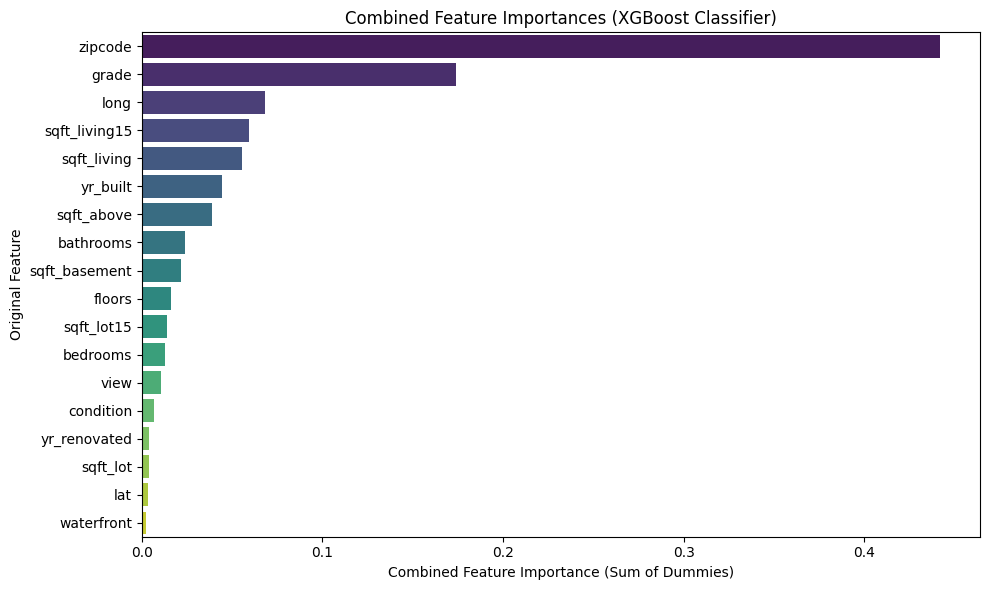

In [19]:
importances = clf.feature_importances_
feature_names = features_df.columns

feat_imp_df = pd.DataFrame({
    'Dummy_Feature': feature_names,
    'Importance': importances
})

original_columns = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors",
                    "waterfront", "view", "condition", "grade", "sqft_above",
                    "sqft_basement", "yr_built", "yr_renovated", "zipcode",
                    "lat", "long", "sqft_living15", "sqft_lot15"]

def map_to_original(dummy_name):
    for orig in original_columns:
        if dummy_name.startswith(orig + "_") or dummy_name == orig:
            return orig
    return dummy_name

feat_imp_df['Original_Feature'] = feat_imp_df['Dummy_Feature'].apply(map_to_original)

combined_imp_df = feat_imp_df.groupby('Original_Feature')['Importance'].sum().reset_index()
combined_imp_df = combined_imp_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=combined_imp_df, x='Importance', y='Original_Feature', hue='Original_Feature', legend=False, palette='viridis')

plt.xlabel('Combined Feature Importance (Sum of Dummies)')
plt.ylabel('Original Feature')
plt.title('Combined Feature Importances (XGBoost Classifier)')
plt.tight_layout()
plt.show()

Create new model based on top 8 features found above

In [21]:
top_8_feature_names = combined_imp_df.head(8)['Original_Feature'].tolist()
print(f"Selected Top 8 Features: {top_8_feature_names}")

features_subset = housing.select(top_8_feature_names)

cat_cols_subset = [col for col, dtype in zip(features_subset.columns, features_subset.dtypes) if dtype == pl.Utf8]
if len(cat_cols_subset) > 0:
    features_subset_dummies = features_subset.to_dummies(columns=cat_cols_subset)
else:
    features_subset_dummies = features_subset.to_dummies()

X_sub = features_subset_dummies.to_numpy()
y_sub = target

X_train_sub, X_test_sub, y_train_sub, y_test_sub = train_test_split(
    X_sub, y_sub, test_size=0.2, random_state=42
)

clf_sub = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
clf_sub.fit(X_train_sub, y_train_sub)

accuracy_sub = clf_sub.score(X_test_sub, y_test_sub)
print(f"New Model Accuracy (Top 8 features only): {accuracy_sub:.4f}")

Selected Top 8 Features: ['zipcode', 'grade', 'long', 'sqft_living15', 'sqft_living', 'yr_built', 'sqft_above', 'bathrooms']


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:44:03] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.



New Model Accuracy (Top 8 features only): 0.8768


Heatmap of new model showing visible accuracy

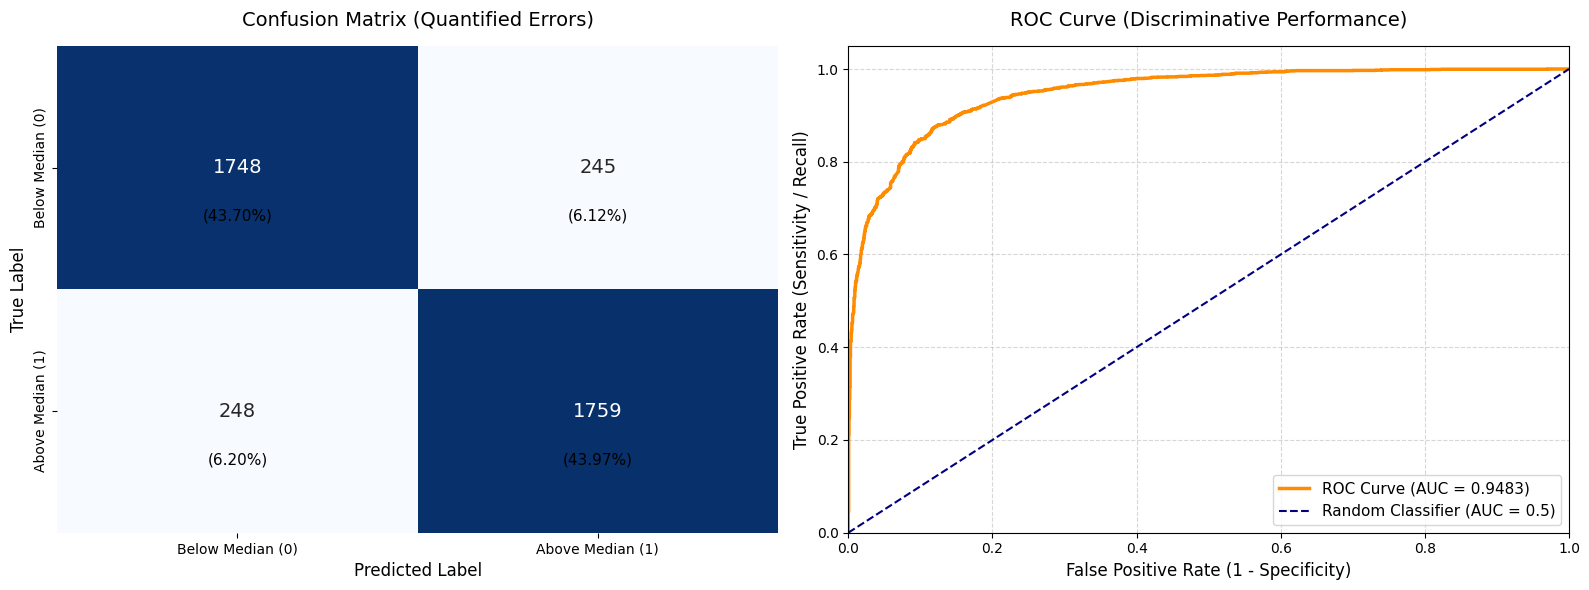

--- Quantifiable Classification Summary ---
              precision    recall  f1-score   support

Below Median       0.88      0.88      0.88      1993
Above Median       0.88      0.88      0.88      2007

    accuracy                           0.88      4000
   macro avg       0.88      0.88      0.88      4000
weighted avg       0.88      0.88      0.88      4000



In [23]:
y_pred_proba = clf_sub.predict_proba(X_test_sub)[:, 1]

y_pred = (y_pred_proba >= 0.5).astype(int)
cm = confusion_matrix(y_test_sub, y_pred)
fpr, tpr, thresholds = roc_curve(y_test_sub, y_pred_proba)
roc_auc = auc(fpr, tpr)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Below Median (0)', 'Above Median (1)'],
    yticklabels=['Below Median (0)', 'Above Median (1)'],
    ax=axes[0],
    cbar=False,
    annot_kws={'size': 14}
)
axes[0].set_title('Confusion Matrix (Quantified Errors)', fontsize=14, pad=15)
axes[0].set_xlabel('Predicted Label', fontsize=12)
axes[0].set_ylabel('True Label', fontsize=12)

total_samples = len(y_test_sub)
for i in range(2):
    for j in range(2):
        count = cm[i, j]
        percentage = (count / total_samples) * 100
        axes[0].text(
            j + 0.5,
            i + 0.7,
            f'({percentage:.2f}%)',
            ha='center',
            va='center',
            color='black' if count < (total_samples / 2) else 'white',
            fontsize=11
        )

axes[1].plot(fpr, tpr, color='darkorange', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Classifier (AUC = 0.5)')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
axes[1].set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
axes[1].set_title('ROC Curve (Discriminative Performance)', fontsize=14, pad=15)
axes[1].legend(loc='lower right', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("--- Quantifiable Classification Summary ---")
print(classification_report(y_test_sub, y_pred, target_names=['Below Median', 'Above Median']))

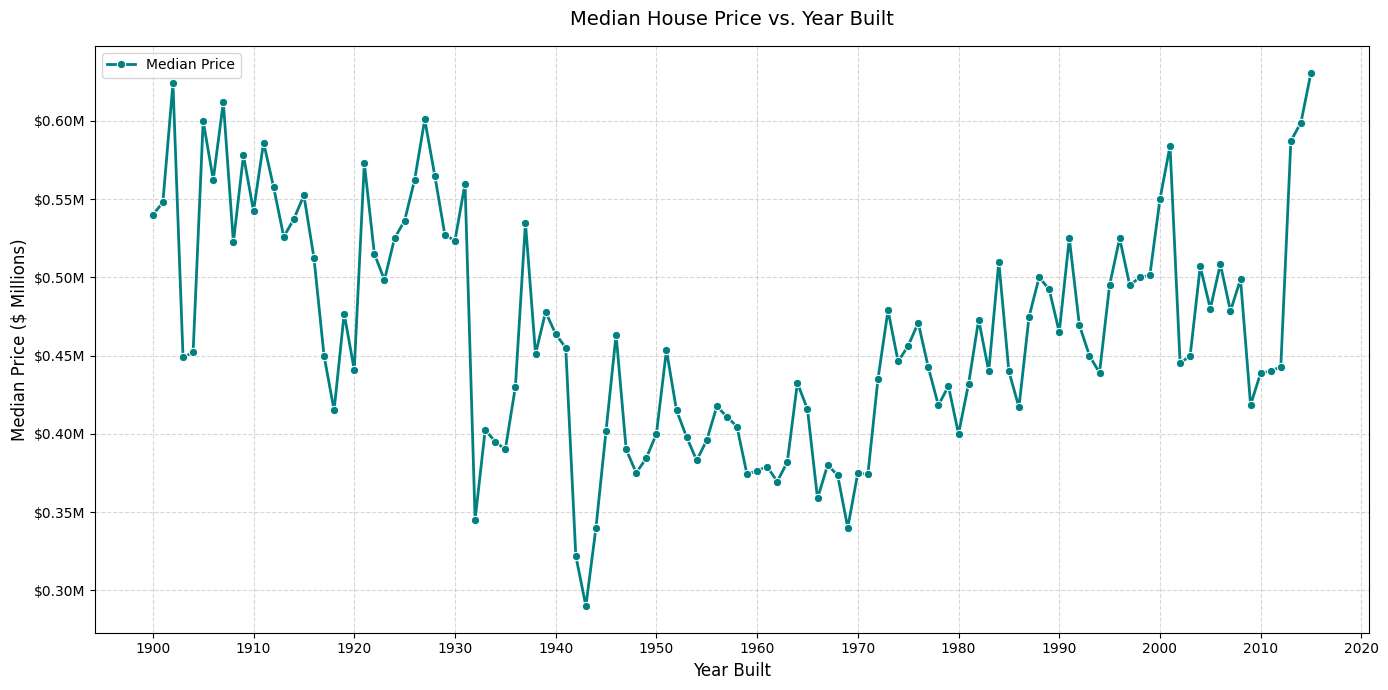

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Group by 'yr_built' and calculate the median price for each year
housing_pd = housing.to_pandas()
median_price_by_year = housing_pd.groupby('yr_built')['price'].median().reset_index()

# Create a line plot with markers to show the median price trend
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=median_price_by_year,
    x='yr_built',
    y='price',
    marker='o',
    color='teal',
    linewidth=2,
    markersize=6,
    label='Median Price'
)

# Customize plot aesthetics
plt.title('Median House Price vs. Year Built', fontsize=14, pad=15)
plt.xlabel('Year Built', fontsize=12)
plt.ylabel('Median Price ($ Millions)', fontsize=12)

# Set x-axis tick breakpoints every 10 years for better legibility
min_year = int(median_price_by_year['yr_built'].min())
max_year = int(median_price_by_year['yr_built'].max())
plt.xticks(np.arange(1900, max_year + 10, 10))

# Formatting the y-axis to display in millions of dollars for better readability
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x*1e-6:.2f}M'))

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

1. The 1933 Drop: The Depth of the Great Depression
Economic Context: The Great Depression, which began with the stock market crash in late 1929, reached its absolute worst economic depth in 1933, with U.S. unemployment peaking at around 25%.
Impact on Housing: Almost all home construction halted. The few houses built in 1933 were typically very small, basic, or built with cheaper materials due to extreme financial scarcity.
Data Effect: Because only a tiny number of highly budget-conscious homes were built that year, the median value of homes constructed in 1933 remains significantly depressed compared to the years before and after.
2. The 1943 Drop: World War II Mobilization
Economic Context: By 1943, the United States was deeply involved in World War II, and the domestic economy was entirely shifted toward the war effort.
Impact on Housing: The War Production Board severely restricted non-essential construction. Domestic building materials (like steel, copper, and high-grade lumber) and skilled labor were strictly rationed and diverted to military use. Any civilian housing that was permitted in 1943 was strictly limited in square footage, designed with minimal materials, or built as rapid, low-cost worker housing near shipyards and military bases.
Data Effect: The lack of premium materials and strict size limits during 1943 created a generation of exceptionally modest, utility-focused homes, which pulls the median price down significantly when looking back at those years.